# SO-SIMBA CDR – Antarctic sea-ice thickness

## Overview

The SO-SIMBA Climate Data Record (CDR) of Antarctic sea-ice thickness and volume is derived from radar altimetry
(Envisat 2002–2012, CryoSat-2 2010–2025). Daily L3C files on the 25 km EASE2 grid (EPSG:6932); the position of each ice parcel (10 km radius) is corrected
for the sea-ice drift between the satellite overpass and the target day (drift-aware gridding).

| | |
|---|---|
| **Producers** | Marion Bocquet, Robert Ricker (NORCE Norwegian Research Centre) |
| **Time coverage** | 11 June 2002 – 31 August 2025, daily |
| **Grid** | 25 km EASE2, Southern Hemisphere (EPSG:6932) |
| **DOI** | [10.21343/pf9r-6d17](https://doi.org/10.21343/pf9r-6d17) |
| **Landing page** | [Arctic Data Centre (MET Norway)](https://adc.met.no/dataset/4e4750fd-66c4-5463-9dcd-5422ea3c8f58) |
| **Data server** | [THREDDS catalogue](https://thredds.met.no/thredds/catalog/arcticdata/SO-SIMBA/SOSIMBA_CDR_SIT_vf/catalog.html) (OPeNDAP, HTTP, WMS) |
| **Zarr store** | `https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_CDR_SIT_vf_<mission>.zarr/` |
| **Licence** | CC-BY-4.0 |
| **Project** | ESA Polar Science Cluster, SO-SIMBA |

This notebook reads the data **remotely, without downloading anything**, from the cloud-optimised **zarr** copy
of the CDR (one store per mission, all days in one dataset):

1. Open the dataset and select one day
2. Map of the sea-ice thickness and its combined uncertainty
3. Time series of the mean sea-ice thickness over a period

The mission is chosen with `MISSION` (`"envisat"` or `"cryosat2"`) at the top; both cover Oct 2010 – Mar 2012.

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import pandas as pd
import xarray as xr

# ---- to adapt
MISSION = "envisat"     # choose the mission: "envisat" (Jun 2002 - Mar 2012) or "cryosat2" (Oct 2010 - Aug 2025)
DATE = "2011-09-15"     # day to map (must be within the period of the chosen mission)

## Data access

The whole record of one mission is a single cloud-optimised **zarr** store on the EarthCODE object storage.
`xarray` opens it lazily: only the chunks you use are transferred, so a map or a multi-year time series is read
directly, without looping over files. Requires the `zarr`, `fsspec`, `aiohttp` and `dask` packages
(`pip install zarr fsspec aiohttp dask`).

In [10]:
ZARR = "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_CDR_SIT_vf_{mission}.zarr/"


def open_zarr(mission=MISSION):
    """Whole record of one mission (all days), opened lazily from the zarr store."""
    return xr.open_dataset(ZARR.format(mission=mission), engine="zarr", chunks={})

## 1. Open the dataset and select one day

In [3]:
ds = open_zarr()                                     # all days of the mission, nothing loaded yet
print(f"{MISSION}: {ds.sizes['time']} days, {ds.time.values[0]:.10} to {ds.time.values[-1]:.10}")
ds_day = ds.sel(time=DATE, method="nearest")         # one day

# variables, units and description
for v in ds_day.data_vars:
    print(f"{v:35s} {ds_day[v].attrs.get('units', ''):8s} {ds_day[v].attrs.get('long_name', '')}")

envisat: 3582 days, 2002-06-11 to 2012-03-31
crs                                          
dist_acquisition                    km       distance between target day and day of data acquisition location
region                              1        region identifier
sea_ice_thickness                   m        thickness of the sea ice layer
sea_ice_thickness_change            m d-1    rate of change in sea ice thickness per day
sea_ice_thickness_change_interp     m d-1    interpolated sea ice thickness change
sea_ice_thickness_change_unc        m d-1    sea ice thickness uncertainty associated with the sea ice thickness change per day
sea_ice_thickness_drift_unc         m        uncertainty of the sea-ice thickness due to the uncertainty of the sea-ice drift
sea_ice_thickness_l2_unc            m        sea ice thickness uncertainty associated with the level2 product
sea_ice_thickness_std               m        standard deviation of sea ice thickness estimates within parcel
sea_ice_thickne

## 2. Maps

The grid is a Lambert azimuthal equal-area projection centred on the South Pole (EASE2, EPSG:6932);
`xc` and `yc` are in metres.

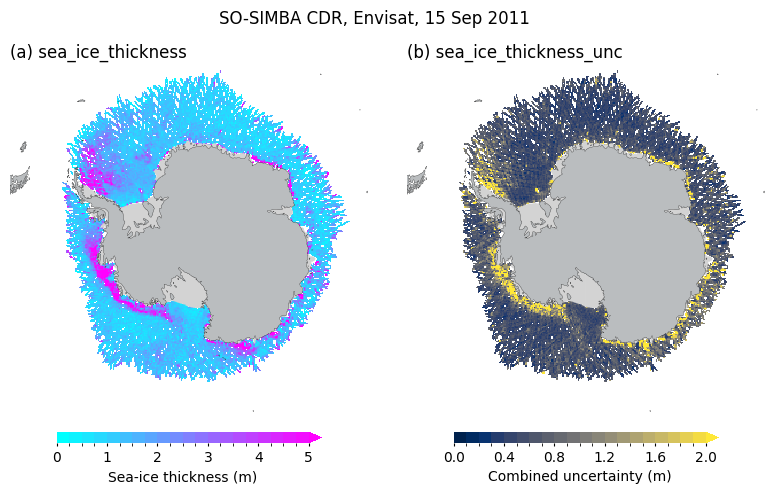

In [4]:
crs = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=-90)
extent = [-3.9e6, 3.9e6, -3.9e6, 3.9e6]   # x0, x1, y0, y1 in metres

land = cfeature.NaturalEarthFeature("physical", "coastline", "50m", facecolor=(0.73, 0.74, 0.75), edgecolor="black")
shelves = cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m", facecolor="lightgray",
                                       edgecolor="lightgray")


def plot_map(ax, da, cmap, vmin, vmax, label, n_steps=20):
    """Map of a 2-D field of the CDR on the EASE2 grid, with n_steps colour levels between vmin and vmax."""
    levels = np.linspace(vmin, vmax, n_steps + 1)
    cmap = plt.get_cmap(cmap, n_steps + 1)                      
    norm = BoundaryNorm(levels, ncolors=cmap.N, extend="max")
    ax.set_extent(extent, crs=crs)
    im = ax.pcolormesh(da.xc, da.yc, da.squeeze(), cmap=cmap, norm=norm, transform=crs,
                       shading="auto", rasterized=True)
    ax.add_feature(shelves, linewidth=0.2, zorder=2)
    ax.add_feature(land, linewidth=0.2, zorder=3)
    ax.axis("off")
    cb = plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02, aspect=25, extend="max")
    cb.set_label(label)
    cb.set_ticks(levels[::4])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2)
    return im


name = {"envisat": "Envisat", "cryosat2": "CryoSat-2"}[MISSION]
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.sea_ice_thickness, "cool", 0, 5, "Sea-ice thickness (m)")
plot_map(axes[1], ds_day.sea_ice_thickness_unc, "cividis", 0, 2, "Combined uncertainty (m)")
axes[0].set_title("(a) sea_ice_thickness", loc="left")
axes[1].set_title("(b) sea_ice_thickness_unc", loc="left")
fig.suptitle(f"SO-SIMBA CDR, {name}, {pd.Timestamp(DATE):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 3. Time series of the mean sea-ice thickness

Mean over all valid grid cells, for every day between `START` and `END`: the period is selected in the store and
averaged in one go (about 20 s for one year).

In [11]:
START, END = "2010-01-01", "2011-12-31"
ds_year = ds.sel(time=slice(START, END))
ts = ds_year.sea_ice_thickness.mean(dim=['yc', 'xc'], skipna=True).compute()
ts

<xarray.DataArray 'sea_ice_thickness' (time: 730)> Size: 3kB
array([1.4543271, 1.4511701, 1.4661123, 1.4675232, 1.4756944, 1.4833045,
       1.4932493, 1.4894664, 1.5030227, 1.5001067, 1.5058323, 1.4980553,
       1.4954426, 1.5280079, 1.5194256, 1.5162241, 1.55153  , 1.5505303,
       1.5525874, 1.5762188, 1.5716281, 1.5739868, 1.5942557, 1.6201692,
       1.6107764, 1.619897 , 1.6347961, 1.6307843, 1.6614275, 1.6749307,
       1.6886225, 1.6950717, 1.7223207, 1.6975427, 1.7066804, 1.7229596,
       1.7289534, 1.7379578, 1.7332493, 1.7015662, 1.687948 , 1.676833 ,
       1.6862446, 1.6925799, 1.6890942, 1.6945438, 1.6758991, 1.6655922,
       1.6419264, 1.5953306, 1.5800999, 1.5533862, 1.5142046, 1.5100937,
       1.4736302, 1.470214 , 1.4620891, 1.4341533, 1.4202498, 1.402949 ,
       1.4008214, 1.3865327, 1.3888766, 1.4002916, 1.4175953, 1.4129809,
       1.4287617, 1.4291699, 1.4343957, 1.4242731, 1.4257255, 1.4328772,
       1.4279544, 1.4297142, 1.410875 , 1.4151727, 1.4338292, 1.4218764,
       1.4201058, 1.4105369, 1.407175 , 1.3965449, 1.4042178, 1.4079432,
       1.4029652, 1.415594 , 1.4335827, 1.4284333, 1.4457428, 1.4465399,
       1.4228342, 1.4195049, 1.4323424, 1.4089421, 1.4053735, 1.3956691,
       1.38654  , 1.372034 , 1.3771164, 1.3759106, 1.3782896, 1.3780425,
       1.3948377, 1.3970268, 1.3890669, 1.383475 , 1.3830178, 1.3728853,
       1.3810446, 1.3750342, 1.3744901, 1.3862339, 1.3767369, 1.371431 ,
       1.3648028, 1.3690856, 1.3696727, 1.3620186, 1.3617008, 1.3691052,
...
       1.6726817, 1.6671635, 1.6636167, 1.6551977, 1.6410459, 1.6358349,
       1.6294421, 1.628288 , 1.6243253, 1.6285123, 1.6216341, 1.6194814,
       1.6199856, 1.6133617, 1.6164219, 1.6207048, 1.6270424, 1.6269081,
       1.6337079, 1.6431583, 1.6380996, 1.6394279, 1.6406829, 1.6385547,
       1.6313874, 1.6337404, 1.6296678, 1.6192341, 1.6097342, 1.6077616,
       1.606777 , 1.6030076, 1.5943668, 1.5950267, 1.5909818, 1.5932148,
       1.5922843, 1.5870925, 1.5862141, 1.5838462, 1.582468 , 1.5791205,
       1.5763941, 1.5699426, 1.5656284, 1.5566926, 1.547348 , 1.5361186,
       1.5243573, 1.5107117, 1.5035417, 1.4930679, 1.4824284, 1.4736584,
       1.4572275, 1.4442707, 1.4299737, 1.4169526, 1.4138114, 1.4042797,
       1.3907254, 1.3807327, 1.3745795, 1.3655144, 1.3556906, 1.3474977,
       1.3401494, 1.3246199, 1.3152821, 1.30629  , 1.2948297, 1.283728 ,
       1.2883275, 1.2742723, 1.262818 , 1.2610668, 1.2628937, 1.2543145,
       1.248075 , 1.2527221, 1.2426484, 1.2458233, 1.2340697, 1.2306366,
       1.2405931, 1.236835 , 1.2363479, 1.2367923, 1.2481871, 1.2455156,
       1.2541301, 1.2578337, 1.2690505, 1.2682116, 1.2784464, 1.2910242,
       1.3071862, 1.3237925, 1.338798 , 1.3530455, 1.3627893, 1.3752257,
       1.3810765, 1.4007181, 1.4189544, 1.4172676, 1.4424269, 1.4557028,
       1.456869 , 1.4757146, 1.4936959, 1.495236 , 1.5181658, 1.5387864,
       1.5522147, 1.5590771, 1.5722543, 1.5991664], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 6kB 2010-01-01T12:00:00 ... 2011-12-31T12:...
Attributes:
    long_name:              thickness of the sea ice layer
    standard_name:          sea_ice_thickness
    units:                  m
    grid_mapping:           crs
    comment:                weighted mean of the sea-ice thickness
    coverage_content_type:  physicalMeasurement

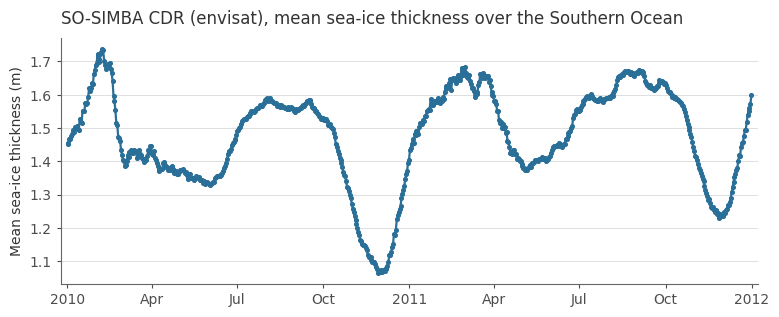

In [12]:
COLOR = "#2a6f97"   # ocean blue
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts.time, ts.values, color=COLOR, lw=1.6)
ax.scatter(ts.time, ts.values, color=COLOR, s=7, zorder=3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel("Mean sea-ice thickness (m)", color="0.2")
ax.set_title(f"SO-SIMBA CDR ({MISSION}), mean sea-ice thickness over the Southern Ocean", loc="left", color="0.2", pad=10)
ax.margins(x=0.01)
plt.show()

## References

Bocquet, M. and Ricker, R.: SO-SIMBA Climate Data record of Antarctic Sea Ice Thickness and Sea Ice Volume,
Norwegian Meteorological Institute / Arctic Data Centre, https://doi.org/10.21343/pf9r-6d17.